<a href="https://colab.research.google.com/github/OJB-Quantum/MuMax3-How-To/blob/main/MuMax%20Notebooks/Temperature_Example_MuMaxPlus.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! echo "This machine runs" $(uname) "with" $(python --version) "and provides the following GPU/CUDA specs:"
! nvidia-smi

In [ ]:
!uv pip install mumaxplus matplotlib numpy

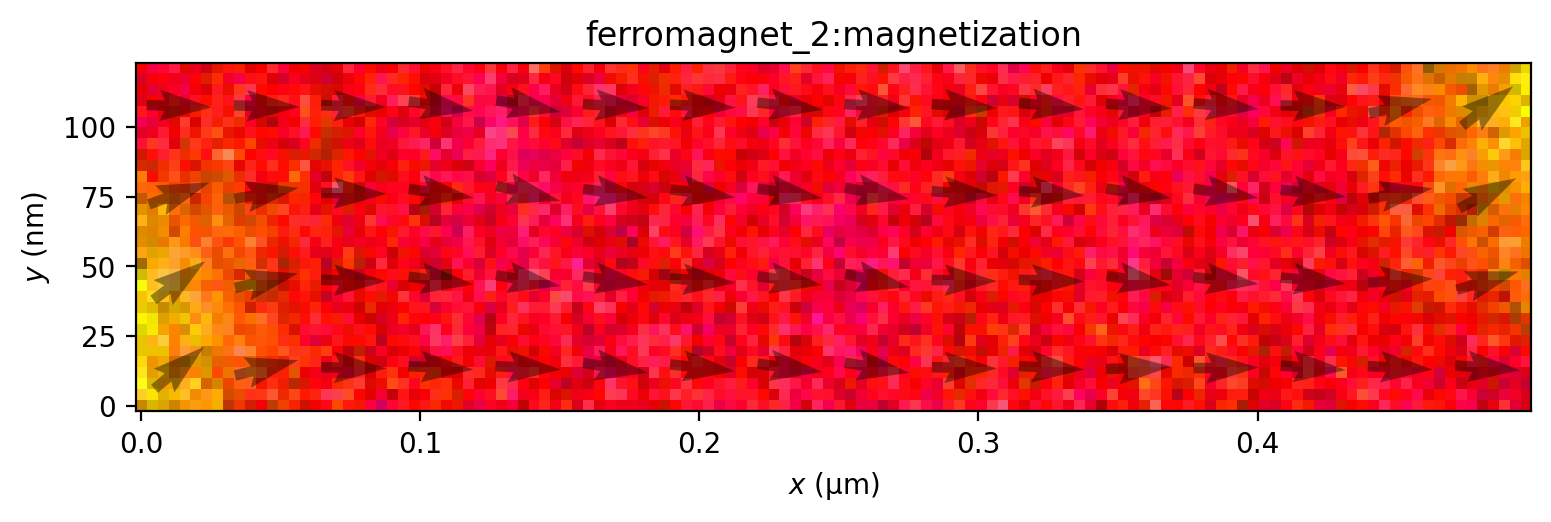

In [5]:
"""This script initializes a ferromagnetic system and plots its transient magnetization field."""

import matplotlib.pyplot as plt
from mumaxplus import Ferromagnet
from mumaxplus import Grid
from mumaxplus import World
from mumaxplus.util import plot_field

plt.rcParams['figure.dpi'] = 200

# DOMAIN SPECIFICATIONS
length = 500e-9
width = 125e-9
thickness = 3e-9
nx = 128
ny = 32
nz = 1

world = World(cellsize=(length / nx, width / ny, thickness / nz))

# FERROMAGNET INITIALIZATION
magnet = Ferromagnet(world, Grid((nx, ny, nz)))
magnet.msat = 800e3
magnet.aex = 13e-12
magnet.alpha = 0.02
magnet.temperature = 200

magnet.magnetization = (1, 0.1, 0)

# SOLVER EXECUTION
world.timesolver.run(1e-10)

# VISUALIZATION RENDERING
plot_field(magnet.magnetization)
plt.show()